# Problem Set 1
### Cheaper food, better nutrition? Evaluating a staple-food subsidy
#### Group: Jose Eduardo Campos Hernandez, Drishti Khemlani, Madeleine Roberts

##### Data import and cleaning

In [1]:
# Import packages
library(tidyverse)
library(gt)
library(fixest)
library(modelsummary)

# Import data
staple_households <- read_csv("staple_households.csv", show_col_types = FALSE)
food_energy <- read_csv("food_energy.csv", show_col_types = FALSE)

# Clean data for analysis
raw_data <- staple_households |>
  pivot_longer(
    cols = c(rice_g, fish_g, vegetables_g, oil_g,
             rice_price_kg, fish_price_kg, vegetables_price_kg, oil_price_kg),
    names_to  = "variable",
    values_to = "value") |>
  mutate(food = str_remove(variable, "_g$|_price_kg$"),
         measure = if_else(str_ends(variable, "_g"), "grams_consumed", "price_kg")) |>
  select(-variable) |>
  pivot_wider(names_from = measure, values_from = value) |> 
  left_join(food_energy, by = "food") |> 
    transmute(household_id, 
              region, 
              treated, 
              wave, 
              baseline_resources, 
              cash_resources,
              food_spending, 
              other_spending, 
              subsidy_cost, 
              food, 
              price_g = price_kg/1000, 
              kcal_per_g,
              grams_consumed,
              food_caloric_intake = grams_consumed*kcal_per_g,
              food_share_spending = (grams_consumed*price_g)/food_spending*100)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## **Question 1: Understand the data and make a prediction**
##### *Before calculating policy effects, record your prediction about how households will respond to cheaper rice and whether calorie intake will increase. State the reasoning and assumptions behind your prediction.*

**Answer:**

We predict that the 25% rice subsidy will initially encourage greater rice consumption through the substitution effect, as rice becomes relatively cheaper than other goods. However, the increase in real purchasing power introduces an income effect, whose direction depends on whether rice is a normal or inferior good. If rice is inferior, the income effect may partially or fully offset the substitution effect. Consequently, the overall effect on rice consumption is theoretically ambiguous.

We tentatively hypothesise that the subsidy will increase total calorie intake, although households may reallocate expenditure towards other foods or non-food consumption. We therefore expect the intervention to affect not only rice demand but potentially the composition of household consumption.

Our empirical analysis will evaluate whether the subsidy changes rice consumption, total calorie intake and the allocation of expenditure across goods.

##### *Explore and audit the dataset. What do you need to check before trusting an analysis of this pilot? Give a concise account of the sample, the policy as implemented and any data issues. Construct a measure of the policy’s stated outcome, explaining its units and any transformations you make.*

**Answer:**

The dataset contains 480 households across two regions, A and B, observed over three survey waves (Before, During and After), resulting in 1,440 household-wave observations. Within each region, 120 households were assigned to treatment and 120 to control, giving a total of 240 households in each group.

In [2]:
  # Sample structure
staple_households |>
  summarise(
    observations = n(),
    households = n_distinct(household_id),
    missing_values = sum(is.na(as.matrix(staple_households)))
  )

# Treatment allocation by region
staple_households |>
  distinct(household_id, region, treated) |>
  count(region, treated)

# Number of waves per household
staple_households |>
  count(household_id) |>
  count(n)

# Duplicate household-wave observations
staple_households |>
  count(household_id, wave) |>
  filter(n != 1)

# Check whether region and treatment stay constant
staple_households |>
  group_by(household_id) |>
  summarise(
    n_regions = n_distinct(region),
    n_treatment_values = n_distinct(treated),
    .groups = "drop"
  ) |>
  filter(n_regions != 1 | n_treatment_values != 1)

  # Check budget consistency and negative values
staple_households |>
  summarise(
    budget_violations = sum(
      abs(food_spending + other_spending - cash_resources) > 1e-6
    ),
    negative_food_quantities = sum(
      if_any(
        c(rice_g, fish_g, vegetables_g, oil_g),
        ~ .x < 0
      )
    ),
    negative_spending = sum(
      food_spending < 0 | other_spending < 0
    )
  )

observations,households,missing_values
<int>,<int>,<int>
1440,480,0


region,treated,n
<chr>,<dbl>,<int>
A,0,120
A,1,120
B,0,120
B,1,120


Storing counts in `nn`, as `n` already present in input
ℹ Use `name = "new_name"` to pick a new name.


n,nn
<int>,<int>
3,480


household_id,wave,n
<chr>,<chr>,<int>


household_id,n_regions,n_treatment_values
<chr>,<int>,<int>


budget_violations,negative_food_quantities,negative_spending
<int>,<int>,<int>
0,0,0


The data audit confirms that there are no missing values, duplicate household-wave observations or survey attrition. All 480 households are observed in all three survey waves, while regional classification and treatment assignment remain constant over time. Furthermore, no negative food consumption quantities or expenditure values are observed, and household spending satisfies the budget identity, with food spending plus other spending equalling available cash resources. These findings indicate that the dataset is structurally consistent with the intended experimental design and contains no issues identified by these checks.

In [3]:
prices <- raw_data |> 
    mutate(treated = ifelse(treated == 1, "Treated", "Control"),
    region = paste("Region", region),
    food = str_to_title(food)) |>
    group_by(food, region, wave, treated) |>
    summarise(price_kg = mean(price_g)*1000, .groups = "drop") |>
    arrange(food)

prices_wide <- prices |>
    pivot_wider(names_from = c(wave, region),
                values_from = price_kg,
                names_glue = "{wave}|{region}") |>
    select(food, treated,
            starts_with("Before"), starts_with("During"), starts_with("After"))

tbl_prices <- prices_wide |>
  gt(rowname_col = "food", groupname_col = "treated") |>
  tab_header(title = "Table 1: Price per kg by food, wave and group") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = -c(treated, food), decimals = 2) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
    # Red box around the subsidised rice price
  tab_style(style = cell_borders(sides = c("top", "bottom"), color = "red", weight = px(2)),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = "left", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region A`,
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = "right", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region B`,
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_text(color = "red", weight = "bold"),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = c("top", "bottom"), color = "red", weight = px(2)),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_borders(sides = "left", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region A`,
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_borders(sides = "right", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region B`,
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_text(color = "red", weight = "bold"),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_source_note("Mean price per kg in currency units. Treated households pay the subsidised rice price only in the During wave.")

IRdisplay::display_html(as_raw_html(tbl_prices))

Mean price per kg in currency units. Treated households pay the subsidised rice price only in the During wave.


**Policy implementation**

Before the intervention, both treatment and control households faced a rice price of 2.4 per kilo. During the intervention, the average rice price for treated households decreased to 1.8 per kilo, representing a 25% reduction, while the control price remained unchanged. After the intervention, rice prices returned to 2.4 per kilo for both groups.

The prices of fish, vegetables and oil remained constant across treatment groups and survey waves. These findings are consistent with the intended implementation of a temporary rice subsidy, with no corresponding changes in the prices of other foods.

**Introduction to baseline balance tests**

Before estimating the policy effects, we examine whether the treatment and control groups are comparable across relevant pre-treatment characteristics. Although random assignment ensures comparability in expectation, differences may arise by chance in a finite sample. Baseline balance tests allow us to assess observed comparability, but do not independently validate the randomisation procedure.

In [4]:
# Analysis to check randomisation
check_data <- raw_data |> 
  mutate(flag = if_else(treated == 1, "Treated", "Control")) |> 
  filter(wave == "Before") |>
  group_by(household_id) |> 
  mutate(total_caloric_intake = sum(food_caloric_intake)) |> 
  ungroup() |> 
  filter(food == "rice")

balance_total <-  check_data |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_A <- check_data |> 
  filter(region == "A") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_B <- check_data |> 
  filter(region == "B") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance <- bind_rows("Total"    = balance_total,
                     "Region A" = balance_A,
                     "Region B" = balance_B,
                     .id = "sample")

# Code for table
labels <- c(baseline_resources = "Baseline resources",
            food_spending      = "Food spending",
            other_spending     = "Other spending",
            total_caloric_intake = "Total calorie intake (kcal/person/day)",
            food_caloric_intake = "Calories from rice (kcal/person/day)",
            food_share_spending  = "Share of spending on rice (%)")

balance_wide <- balance |> 
  mutate(Variable   = unname(labels[name]),
         Treatment  = Treated,
         Comparison = Control,
         `T-stat`   = paste0(sprintf("%.2f", t_stat), signif)) |> 
  select(sample, Variable, Treatment, Comparison, `T-stat`) |> 
  pivot_wider(names_from  = sample,
              values_from = c(Treatment, Comparison, `T-stat`),
              names_glue  = "{sample}|{.value}") |> 
  select(Variable, starts_with("Total"), starts_with("Region A"), starts_with("Region B"))

tbl1 <- balance_wide |> 
  gt(rowname_col = "Variable") |> 
  tab_header(title = "Table 2: Covariate balance before treatment") |> 
  tab_spanner_delim(delim = "|") |> 
  fmt_number(columns = matches("Treatment|Comparison"), decimals = 2) |> 
  cols_align(align = "center") |> 
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |> 
  opt_row_striping() |> 
  tab_source_note("Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01")

IRdisplay::display_html(as_raw_html(tbl1))

"Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01"


Table 1 reports treatment and control group means for six baseline variables, together with Welch two-sample t-statistics. The differences in baseline resources, food spending, other spending, total calorie intake, rice calorie intake and rice expenditure share are small and statistically insignificant at conventional significance levels. This pattern also holds within Regions A and B. The findings are consistent with the randomised assignment, although statistically insignificant differences do not establish exact equality between groups.

Outcome variable construction

The primary outcome is total daily calorie intake per person, measured in kilocalories per person per day (kcal/person/day). For each household-wave observation, we multiply the quantity of rice, fish, vegetables and oil consumed (in grams per person per day) by their respective energy conversion factors of 3.6, 1.2, 0.3 and 9.0 kcal/g, and sum the resulting values. This measures total calorie intake across the four food categories rather than rice consumption alone.

In [5]:
calorie_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(
    total_calories = sum(food_caloric_intake),
    .groups = "drop"
  )

## Question 2: Explore the data
*Before evaluating the policy, explore the main features of the data. Choose a small set of descriptive tables and figures that help you understand households’ consumption, resources and spending, and how these vary across the sample and over time. Describe the patterns you find most informative or surprising. What questions do they raise? How should these patterns inform your subsequent policy evaluation? Explain why you selected each table or figure.*

In [6]:
labels <- c(N              = "Households",
            cash_resources = "Cash resources (per person/day)",
            food_spending  = "Food spending (per person/day)",
            other_spending = "Other spending (per person/day)",
            rice_g         = "Rice consumed (g/person/day)",
            total_calories = "Calorie intake (kcal/person/day)")

# Means by wave and group
descriptive <- staple_households |>
  mutate(total_calories = 3.6 * rice_g + 1.2 * fish_g + 0.3 * vegetables_g + 9 * oil_g,
         group = if_else(treated == 1, "Treated", "Control"),
         wave  = factor(wave, levels = c("Before", "During", "After"))) |>
  group_by(wave, group) |>
  summarise(N              = n(),
            cash_resources = mean(cash_resources),
            food_spending  = mean(food_spending),
            other_spending = mean(other_spending),
            rice_g         = mean(rice_g),
            total_calories = mean(total_calories),
            .groups = "drop")

# One row per variable, one column per wave and group
descriptive_wide <- descriptive |>
  pivot_longer(-c(wave, group), names_to = "name") |>
  mutate(Variable = factor(labels[name], levels = labels)) |>
  select(-name) |>
  pivot_wider(names_from  = c(wave, group),
              values_from = value,
              names_glue  = "{wave}|{group}") |>
  arrange(Variable) |>
  select(Variable, starts_with("Before"), starts_with("During"), starts_with("After"))

tbl_desc <- descriptive_wide |>
  gt(rowname_col = "Variable") |>
  tab_header(title = "Table 3: Descriptive statistics by wave and group") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = -Variable, decimals = 2) |>
  fmt_number(columns = -Variable, rows = Variable == "Households", decimals = 0) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
  tab_source_note("Means by wave and group, both regions. Calorie intake = 3.6 × rice + 1.2 × fish + 0.3 × vegetables + 9 × oil, in grams per person per day. The subsidy applies only to treated households in the During wave.")

IRdisplay::display_html(as_raw_html(tbl_desc))

"Means by wave and group, both regions. Calorie intake = 3.6 × rice + 1.2 × fish + 0.3 × vegetables + 9 × oil, in grams per person per day. The subsidy applies only to treated households in the During wave."


**Interpretation of Table 3: Descriptive Statistics**

Table 2 presents average household resources, food and non-food expenditure, rice consumption and total calorie intake across treatment groups and survey waves. Each group contains 240 households per wave. These variables were selected to examine household purchasing power, expenditure allocation and nutritional outcomes before, during and after the intervention.

Before the subsidy, treatment and control households exhibited similar consumption and expenditure patterns. During the intervention, average rice consumption among treated households declined from 497.72 to 459.97 grams per person per day, while total calorie intake fell from 2,133.44 to 2,051.55 kcal per person per day. In comparison, control households experienced smaller declines in both variables. Interestingly, treated households' food expenditure increased from 2.69 to 2.76 currency units per person per day, despite their lower rice consumption and calorie intake.

Following the withdrawal of the subsidy, rice consumption and total calorie intake returned close to their baseline levels in both groups. These patterns raise the possibility that households adjusted their consumption bundles in response to changing relative prices, potentially reallocating expenditure towards other foods. However, these descriptive statistics cannot establish the underlying mechanism or the causal effect of the subsidy.

The observed differences motivate a subsequent evaluation comparing changes in outcomes between treated and control households, while examining whether changes in food composition help explain the observed patterns.

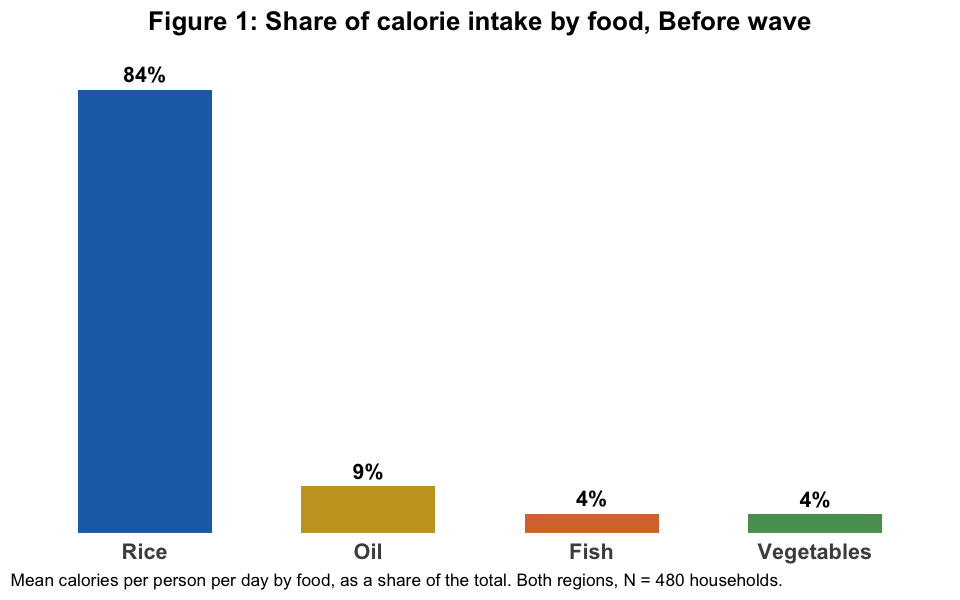

In [7]:
options(repr.plot.width = 8, repr.plot.height = 5)

# Data: share of calories by food in the Before wave, both regions
food_composition <- raw_data |>
  filter(wave == "Before") |>
  group_by(food) |>
  summarise(mean_calories = mean(food_caloric_intake), .groups = "drop") |>
  mutate(calorie_share = mean_calories / sum(mean_calories),
         food = fct_reorder(str_to_title(food), calorie_share, .desc = TRUE))

# Bars ordered from largest to smallest share, labelled with their value
ggplot(food_composition, aes(food, calorie_share, fill = food)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = scales::percent(calorie_share, accuracy = 1)),
            vjust = -0.5, fontface = "bold", size = 4.5) +

  # Same food colours as in the other figures
  scale_fill_manual(values = c(Rice       = "#1f6fb4",
                               Oil        = "#c9a227",
                               Fish       = "#d9773b",
                               Vegetables = "#5a9e5f"),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +

  # Titles and notes
  labs(title = "Figure 1: Share of calorie intake by food, Before wave",
       x = NULL, y = NULL,
       caption = "Mean calories per person per day by food, as a share of the total. Both regions, N = 480 households.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(),
        axis.text.y = element_blank(),
        axis.text.x = element_text(size = 13, face = "bold"),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

**Interpretation of Figure 1**

Figure 1 illustrates the composition of average daily calorie intake before the intervention. Rice accounts for approximately 84% of total calories consumed, followed by oil, fish and vegetables, which contribute substantially smaller shares.

The predominance of rice suggests that household nutrition is highly dependent on staple-food consumption. Consequently, changes in rice demand may have a substantial influence on total calorie intake, making the rice subsidy particularly relevant to the government's nutritional objective.

However, the importance of rice in the baseline diet does not necessarily imply that a reduction in its price will increase calorie intake. Households may reallocate consumption towards other foods as their purchasing power increases. This raises the question of whether changes in dietary composition can offset changes in rice consumption, which will be investigated in the subsequent analysis.

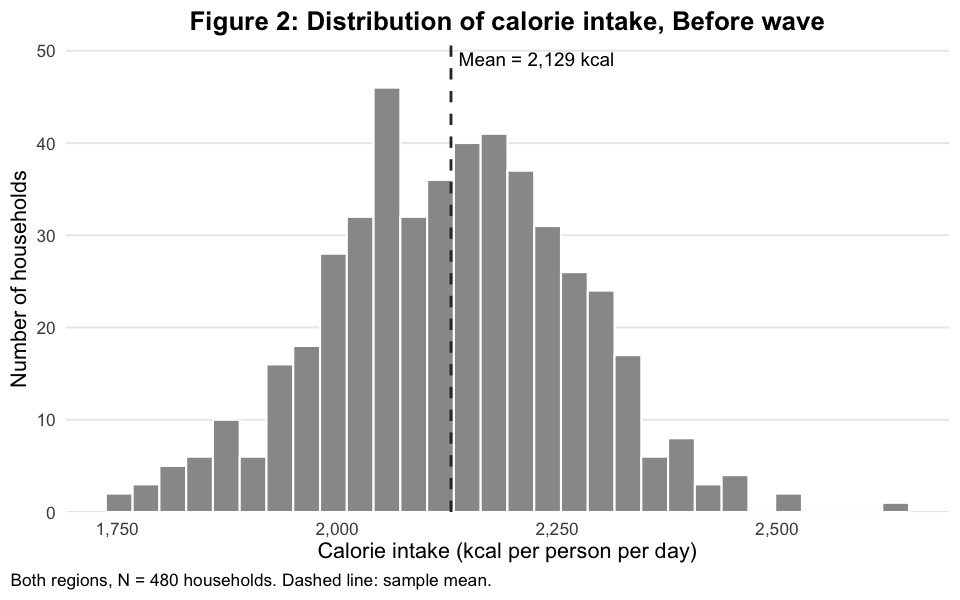

In [8]:
options(repr.plot.width = 8, repr.plot.height = 5)

# Data: total calories per household in the Before wave
baseline_calories <- raw_data |>
  filter(wave == "Before") |>
  group_by(household_id) |>
  summarise(total_calories = sum(food_caloric_intake), .groups = "drop")

mean_kcal <- mean(baseline_calories$total_calories)

# Histogram with the sample mean
ggplot(baseline_calories, aes(total_calories)) +
  geom_histogram(bins = 30, fill = "grey60", colour = "white") +
  geom_vline(xintercept = mean_kcal, linetype = "dashed", colour = "grey20", linewidth = 0.8) +
  annotate("text", x = mean_kcal, y = Inf,
           label = paste0("Mean = ", format(round(mean_kcal), big.mark = ","), " kcal"),
           hjust = -0.05, vjust = 1.5, size = 4) +

  # Scales: bars start at the base, thousands separator on the x axis
  scale_x_continuous(labels = scales::comma) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +

  # Titles and notes
  labs(title = "Figure 2: Distribution of calorie intake, Before wave",
       x = "Calorie intake (kcal per person per day)", y = "Number of households",
       caption = "Both regions, N = 480 households. Dashed line: sample mean.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

**Interpretation of Figure 2**

Figure 2 presents the distribution of total daily calorie intake across the 480 households before the intervention. The distribution is approximately unimodal, with most households consuming between 2,000 and 2,300 kcal per person per day. However, calorie intake varies considerably, with observations ranging from approximately 1,750 to 2,650 kcal per person per day.

This variation suggests that average calorie intake may conceal meaningful differences in households' initial consumption levels. Consequently, the subsidy may have heterogeneous implications for households with relatively low versus high baseline calorie intake.

These findings motivate further investigation into whether the policy's effects differ according to initial household circumstances, rather than relying exclusively on an overall average treatment effect.

**Implications for the policy evaluation**

The descriptive analysis highlights three important features of the pilot. First, rice constitutes the dominant source of household calories, making changes in rice consumption particularly relevant to the policy's nutritional objective. Second, consumption and expenditure patterns vary across survey waves, with treated households exhibiting lower average rice consumption and calorie intake during the intervention. Third, baseline calorie intake differs across households, suggesting that average outcomes may conceal heterogeneity in responses.

These findings motivate an evaluation that compares changes in calorie intake between treatment and control households, accounts for common changes over time, and considers whether responses differ across household characteristics. However, the descriptive evidence alone cannot establish whether the subsidy caused the observed changes.

## Question 3: Design a credible evaluation
*What comparison would allow you to assess whether the subsidy achieved its objective? Describe the outcome you will evaluate, the counterfactual you need and how the available data can help you approximate it. Explain why your comparison is informative about the policy rather than simply about differences between households or changes over time. State the assumptions your interpretation requires. Choose the tables or plots that would make your evaluation convincing to someone who has not seen the data.*

We do a DiD (difference-in-differences) as our empirical strategy to compare changes in caloric intakes for treatment and control groups during and after. DiDs are good because the method exploits some naturally occurring events that change the treatment status of some units over time.

Necessary ingredients:

• Need an event that affects only a sub-population.

• Observe the outcome of interest before and after the treatment.

• Observe the outcome of interest for both treated and untreated groups.


$$Y_{it} = \alpha_i + \lambda_{r(i)t} + \beta_D\,(T_i \times \text{During}_t) + \beta_A\,(T_i \times \text{After}_t) + \varepsilon_{it}$$

where:

- $Y_{it}$ is the **total** calorie intake of household $i$ in wave $t$, in kcal per person per day, summed over rice, fish, vegetables and oil.
- $\alpha_i$ is a household fixed effect, which absorbs every household characteristic that does not change across waves.
- $\lambda_{r(i)t}$ is a region $\times$ wave fixed effect, which absorbs shocks common to all households in a region in a given wave. Randomisation was done within region, so this matches the design.
- $T_i = 1$ if household $i$ was randomly assigned to the subsidy, and $0$ otherwise.
- $\text{During}_t$ and $\text{After}_t$ are wave indicators. The Before wave is the omitted reference.
- Standard errors are clustered by household, because each household is observed three times.

Including region and time period fixed effects allow our comparison to be informative about the policy because we are controlling for differences between households and changes over time.


DiD ssumptions required:
Unobservables that affect the outcome do not vary differently in time between treated and control units. Without the treatment, the outcome of the treated control units would have changed by the same amount. The potential outcome (y0) or (y1) of the treated and control units change by the same amount between periods 0 and 1 = the Parallel Trends Assumption (PTA).

The PTA translates to:

• Unobservables that affect the outcome in average do not vary differently in
time between treated and control units

• Without the treatment, the average outcome of the treated and control units
would have changed by the same amount

Parallel trends holds by design in expectation, because randomisation makes the two groups the same in every way apart from the subsidy. Table 1 is our evidence.

## Question 4: Assess the evidence
*Carry out your evaluation and report the direction and size of the estimated policy effect. How strong is the evidence for your conclusion? Address uncertainty in a way you can explain, taking account of how the observations were collected.*

*Decide whether a single overall result adequately describes the pilot. Investigate any differences in responses that you think matter for the policy decision, and justify your choices. Revisit your initial prediction: what did you learn, and what remains unresolved?*

Using consumption surveys gathered in Before, During, and after Waves, we found no evidence that the subsidy improved calorie intake for the pooled sample and, in fact, it reduced it. We found that, during the subsidy, calorie intake of trated households fell by 46 kcal,  with a statistically significant (Table 4 and Figures 3a and 3b). We considered clustered standard errors since each housegold is observed in the three waves and its observations are not independent.

Considering the regions separately, we found that households in Region A reduced their calorie intake by 127 kcal per person per day in response to the price subsidy. In contrast, Region B experienced an increase of calorie intake in 35 kcal. In both regions, the effect disappears after subsidy ends: as shown in Table 4, the After-wave coefficients are small and not statiscally significant.

In addition, we tested whether the effect of the subsidy differs between regions and found that the effect in region B exceeds the effect in Region B by 161.5 kcal, a large and statiscally significant difference. This shows that the pooled effect averages a large decline in Region A and a small raise in Region B.

In [9]:
regression_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(total_caloric_intake = sum(food_caloric_intake), .groups = "drop") |>
  mutate(wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"),
         region_b    = as.integer(region == "B"))

did <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
               household_id + region^wave,
             data = regression_data, cluster = ~household_id)

did_a <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "A"), cluster = ~household_id)

did_b <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "B"), cluster = ~household_id)

did_diff <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after +
                    treated:wave_during:region_b + treated:wave_after:region_b |
                    household_id + region^wave,
                  data = regression_data, cluster = ~household_id)

tbl5 <- modelsummary(list("Pooled" = did, "Region A" = did_a, "Region B" = did_b, "Difference" = did_diff),
                     coef_map = c("treated:wave_during"          = "Treated × During",
                                  "treated:wave_after"           = "Treated × After",
                                  "treated:wave_during:region_b" = "Treated × During × Region B",
                                  "treated:wave_after:region_b"  = "Treated × After × Region B"), # nolint
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 4: Effect of the rice subsidy on calorie intake, by region") |>
  tab_source_note("Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl5))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.


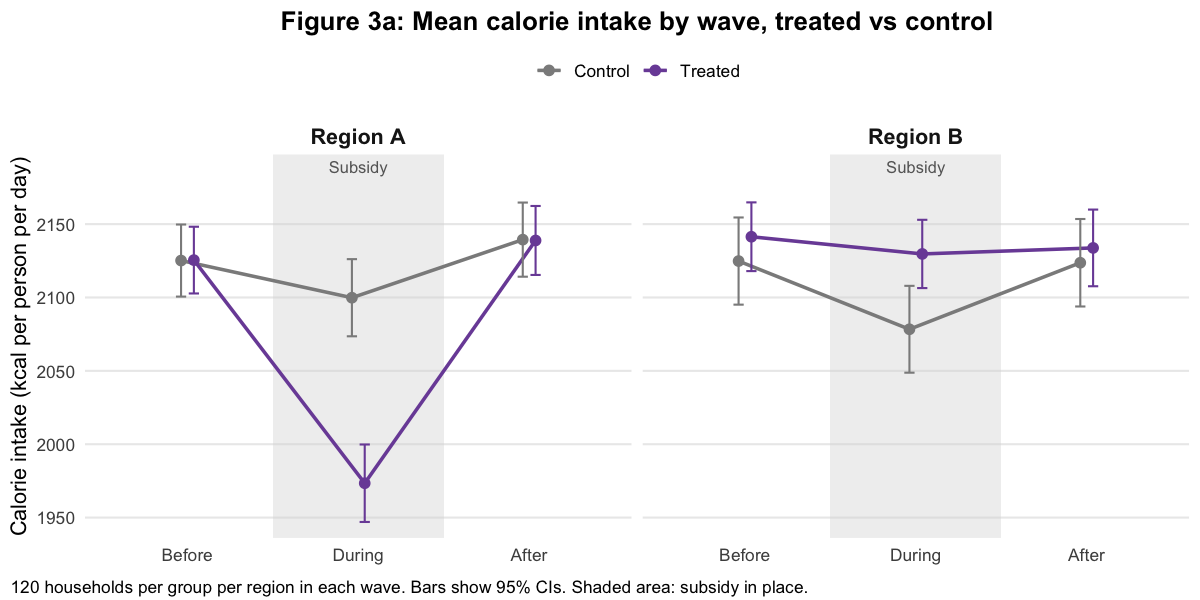

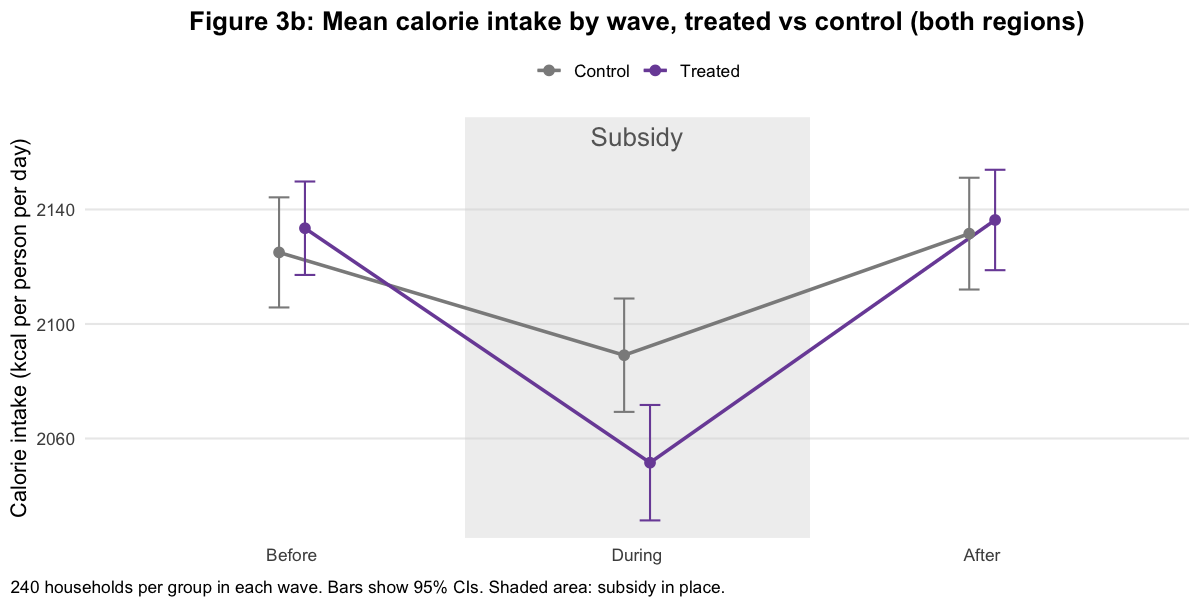

In [17]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# ---- By region ----

# Data: mean and SE of calorie intake by region, wave and group
regression_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(region, wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 3.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # One panel per region
  facet_wrap(~ region) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 3a: Mean calorie intake by wave, treated vs control",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")

# ---- Both regions ----

# Data: mean and SE of calorie intake by wave and group
regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 5.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 3b: Mean calorie intake by wave, treated vs control (both regions)",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "240 households per group in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")

## Question 5: Develop an economic explanation
*How could households’ choices generate the pattern you found? Develop an explanation using the standard consumer choice problem. Specify the relevant goods, the budget constraint and the assumptions about preferences that your argument needs.*

*Use a clearly labelled budget-line and indifference-curve diagram to explain how the price change affects the chosen bundle. Discuss the roles of the substitution and income effects, and whether your explanation requires any goods to be normal or inferior. Connect the logic to your empirical findings. You do not need to estimate a utility function.*

**Economic set-up.** We model a household that chooses between two goods: rice, the staple, and fish, a preferred food that stands for the more costly items in the diet. Rice is the cheapest source of calories (Table 1), while fish offers taste and variety at a much higher cost per calorie. The household divides its budget between the two goods, so the budget constraint is p_rice × rice + p_fish × fish = budget; the subsidy lowers p_rice by 25% for treated households. Preferences reflect two motives: the household needs a minimum level of calories, which rice supplies cheaply, and it values the taste of fish once that minimum is met.

A lower rice price affects the household through two channels. The substitution effect raises rice consumption, since rice becomes cheaper relative to fish. The income effect works through purchasing power: at the new price the household can still afford its original bundle and has resources left over. If rice is an inferior good, the household uses these resources to move away from rice and toward fish. When rice absorbs a large share of the budget, the subsidy frees substantial resources and the income effect can outweigh the substitution effect; rice consumption then falls despite the lower price, and rice behaves as a Giffen good. Jensen and Miller (2011) document this mechanism among poor households in China.

This framework accounts for the patterns in both regions. In region A, treated households cut rice and vegetables and sharply increase fish consumption during the subsidy (tables 5 and 6): the pattern is consistent with a strong negative income effect, potentially yielding Giffen-type behaviour, and calorie intake falls (Figure 4). The separate income and substitution effects are not identified by this design. In region B, rice consumption does not change significantly: the two effects roughly offset each other, and the freed resources go mainly to oil and, to a lesser extent, fish. Since oil is the most calorie-dense food, calorie intake rises. The two regions therefore differ in where the freed resources go: toward fish, a costly source of calories, in region A, and toward oil, a dense one, in region B. The data do not reveal why preferences differ across regions; differences in the budget share of rice or in diet composition (Table 2) are candidate explanations.

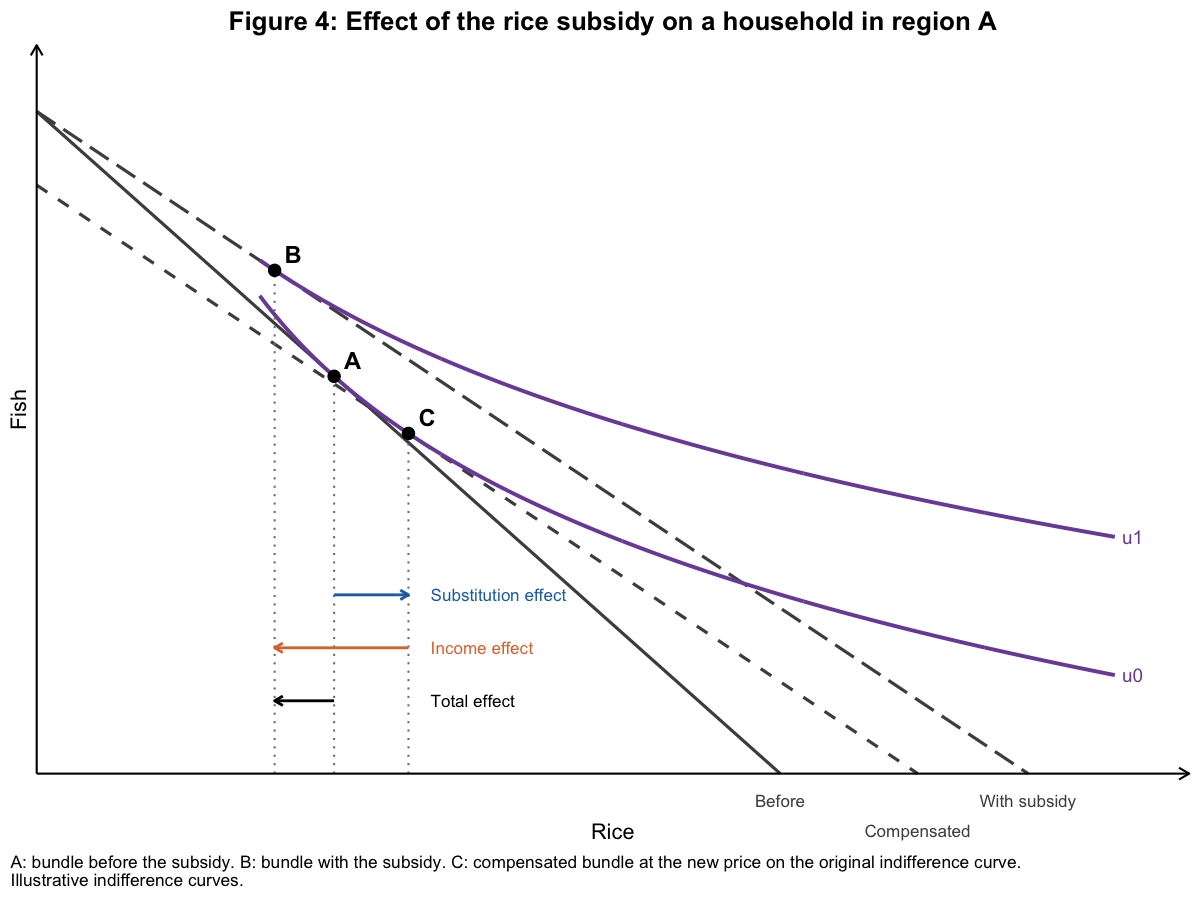

In [21]:
b <- 3
g <- 3
m <- 10
p_fish <- 1
p_old  <- 1
p_new  <- 0.75

ic <- function(x, a, e) a - b * log(x - g + e)

# A: tangency with the original budget (slope -1)
xA <- 4;  yA <- (m - p_old * xA) / p_fish
e0 <- b / p_old - (xA - g);  a0 <- yA + b * log(xA - g + e0)

# B: tangency with the subsidy budget (slope -0.75), with less rice than A
xB <- 3.2;  yB <- (m - p_new * xB) / p_fish
e1 <- b / p_new - (xB - g);  a1 <- yB + b * log(xB - g + e1)

# C: tangency of the original curve with a budget at the new price
xC <- g + b / p_new - e0;  yC <- ic(xC, a0, e0)
m_comp <- p_new * xC + p_fish * yC

# Budget lines: each one goes from its fish intercept to its rice intercept
budgets <- tibble(
  line  = c("before", "subsidy", "compensated"),
  label = c("Before", "With subsidy", "Compensated"),
  y_int = c(m, m, m_comp) / p_fish,
  x_int = c(m / p_old, m / p_new, m_comp / p_new),
  y_lab = c(-0.4, -0.4, -0.85))

# Indifference curves start at the subsistence level
x_grid <- seq(g, 14.5, length.out = 600)

curves <- bind_rows(
  tibble(x = x_grid, y = ic(x_grid, a0, e0), line = "u0"),
  tibble(x = x_grid, y = ic(x_grid, a1, e1), line = "u1"))

points <- tibble(x = c(xA, xC, xB), y = c(yA, yC, yB), label = c("A", "C", "B"))

# Diagram
options(repr.plot.width = 10, repr.plot.height = 7.5)

ggplot() +

  # Rice subsistence level
 #annotate("segment", x = g, xend = g, y = 0, yend = 10.5, linetype = "dashed", colour = "grey60") +
 # annotate("text", x = g - 0.15, y = 10.5, label = "Rice subsistence level",
  #         hjust = 1, colour = "grey40", size = 3.6) +

  # Budget lines from intercept to intercept, labelled below the rice axis
  geom_segment(data = budgets, aes(x = 0, y = y_int, xend = x_int, yend = 0, linetype = line),
               colour = "grey30", linewidth = 0.9) +
  geom_text(data = budgets, aes(x = x_int, y = y_lab, label = label), colour = "grey30", size = 3.6) +

  # Indifference curves, labelled at their right end
  geom_line(data = curves, aes(x, y, group = line), colour = "#7b4fa6", linewidth = 1.1) +
  annotate("text", x = 14.6, y = c(ic(14.5, a0, e0), ic(14.5, a1, e1)), label = c("u0", "u1"),
           colour = "#7b4fa6", hjust = 0, size = 4) +

  # Bundles and guides to the rice axis
  annotate("segment", x = points$x, xend = points$x, y = 0, yend = points$y,
           linetype = "dotted", colour = "grey50") +
  geom_point(data = points, aes(x, y), size = 3) +
  geom_text(data = points, aes(x, y, label = label),
            nudge_x = 0.25, nudge_y = 0.25, fontface = "bold", size = 5) +

  # Substitution, income and total effects on rice, labelled to the right of the arrows
  annotate("segment", x = xA, xend = xC, y = 2.7, yend = 2.7,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#1f6fb4", linewidth = 0.8) +
  annotate("segment", x = xC, xend = xB, y = 1.9, yend = 1.9,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#d9773b", linewidth = 0.8) +
  annotate("segment", x = xA, xend = xB, y = 1.1, yend = 1.1,
           arrow = arrow(length = unit(0.2, "cm")), colour = "black", linewidth = 0.8) +
  annotate("text", x = xC + 0.3, y = c(2.7, 1.9, 1.1),
           label = c("Substitution effect", "Income effect", "Total effect"),
           colour = c("#1f6fb4", "#d9773b", "black"), hjust = 0, size = 3.6) +

  # Scales: axes start at the origin; clip = "off" lets labels sit below the axis
  scale_linetype_manual(values = c(before = "solid", subsidy = "longdash", compensated = "dashed"),
                        guide = "none") +
  coord_cartesian(xlim = c(0, 15.5), ylim = c(0, 11), expand = FALSE, clip = "off") +

  # Titles and notes
  labs(title = "Figure 4: Effect of the rice subsidy on a household in region A",
       x = "Rice", y = "Fish",
       caption = "A: bundle before the subsidy. B: bundle with the subsidy. C: compensated bundle at the new price on the original indifference curve.\nIllustrative indifference curves.") +

  # Textbook style: axes only, no numbers or grid
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(),
        axis.text = element_blank(),
        axis.line = element_line(colour = "black", arrow = arrow(length = unit(0.25, "cm"))),
        axis.title.x = element_text(margin = margin(t = 30)),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

## Question 6: Look for evidence of the mechanism
*Turn your explanation into predictions that you can investigate in the data. What patterns would strengthen it? What would cast doubt on it? Design and present the tables, plots or other comparisons that you judge most informative, and explain what each one establishes.*

*Consider at least one plausible alternative explanation and assess how far the available evidence distinguishes between the two. Be precise about the difference between describing a pattern and establishing why households chose it. Revise your explanation if your evidence calls for it, and identify any additional information you would need.*

It is important to check which changes in food consumption explain the variations in calorie intake (Tables 5 and 6 and the food-consumption figures). Compared with control households, treated households in region A show the following changes during the subsidy:

- Consumption of rice and vegetables falls by 56.5 and 9.2 grams per person per day, respectively.
- Consumption of oil and fish rises by 0.6 and 61.6 grams per person per day, respectively.

In region B we find:

- No significant change in the grams consumed of rice and vegetables.
- Consumption of oil and fish rises by 2.1 and 3.2 grams per person per day, respectively.

All of these changes disappear in the After wave.

In [12]:
food_data <- raw_data |>
  mutate(wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

regression_per_food <- function(f, r) {
  feols(grams_consumed ~ treated:wave_during + treated:wave_after | household_id + wave,
        data = filter(food_data, food == f, region == r), cluster = ~household_id)
}

tbl6 <- modelsummary(list("Rice, Region A" = regression_per_food("rice", "A"),
                          "Rice, Region B" = regression_per_food("rice", "B"),
                          "Fish, Region A" = regression_per_food("fish", "A"),
                          "Fish, Region B" = regression_per_food("fish", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 5: Effect of the rice subsidy on rice and fish consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl6))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


In [13]:
tbl7 <- modelsummary(list("Vegetables, Region A" = regression_per_food("vegetables", "A"),
                          "Vegetables, Region B" = regression_per_food("vegetables", "B"),
                          "Oil, Region A" = regression_per_food("oil", "A"),
                          "Oil, Region B" = regression_per_food("oil", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 6: Effect of the rice subsidy on vegetables and oil consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl7))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


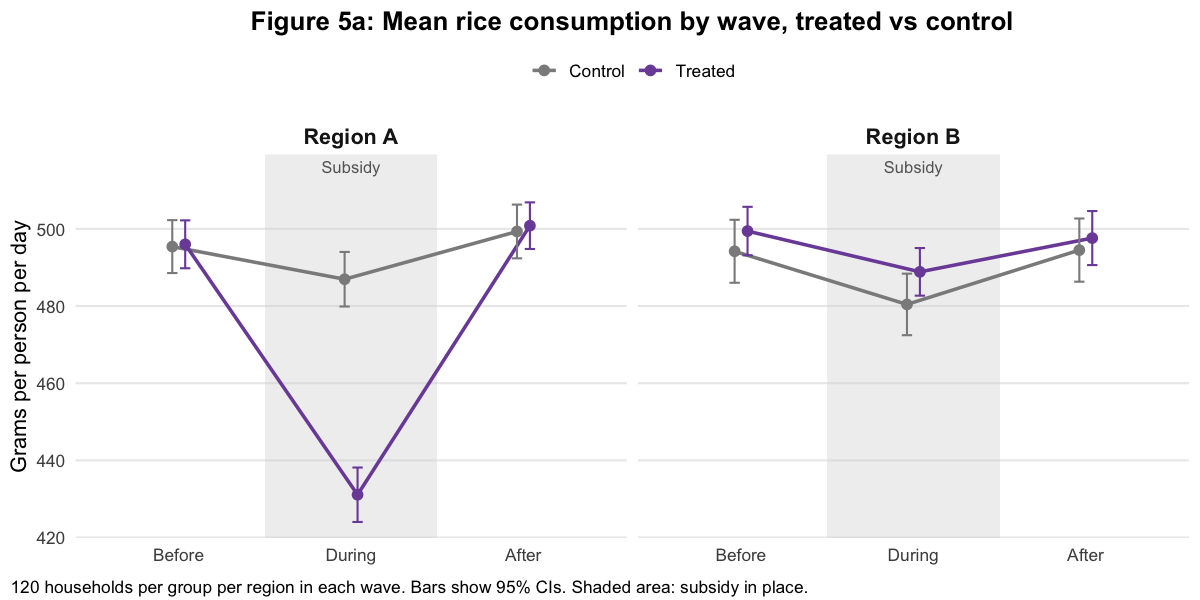

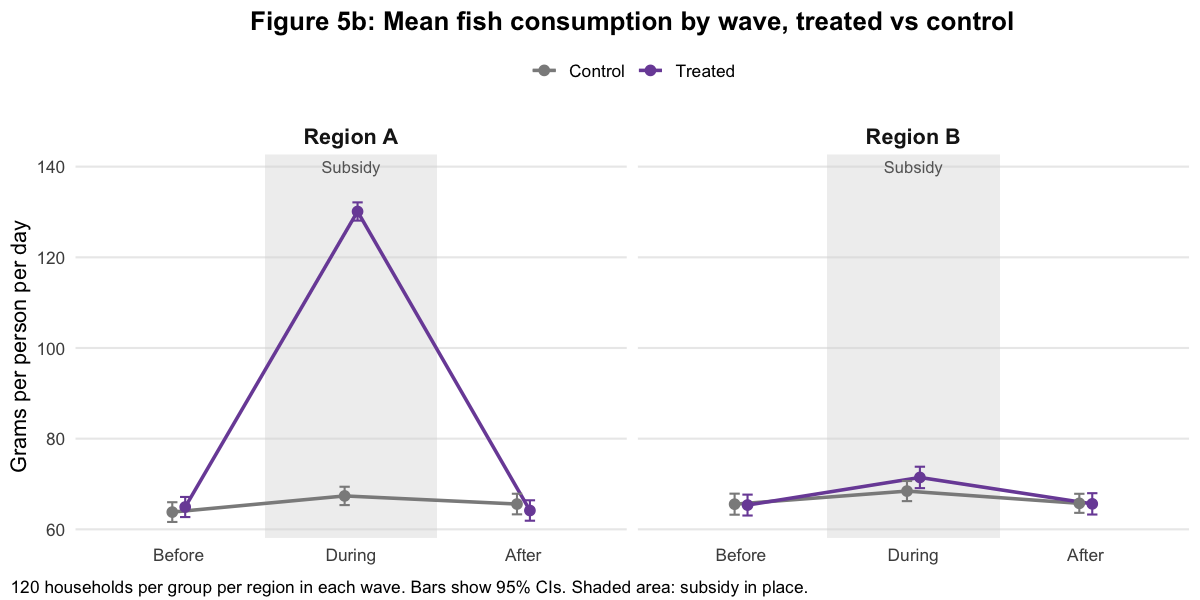

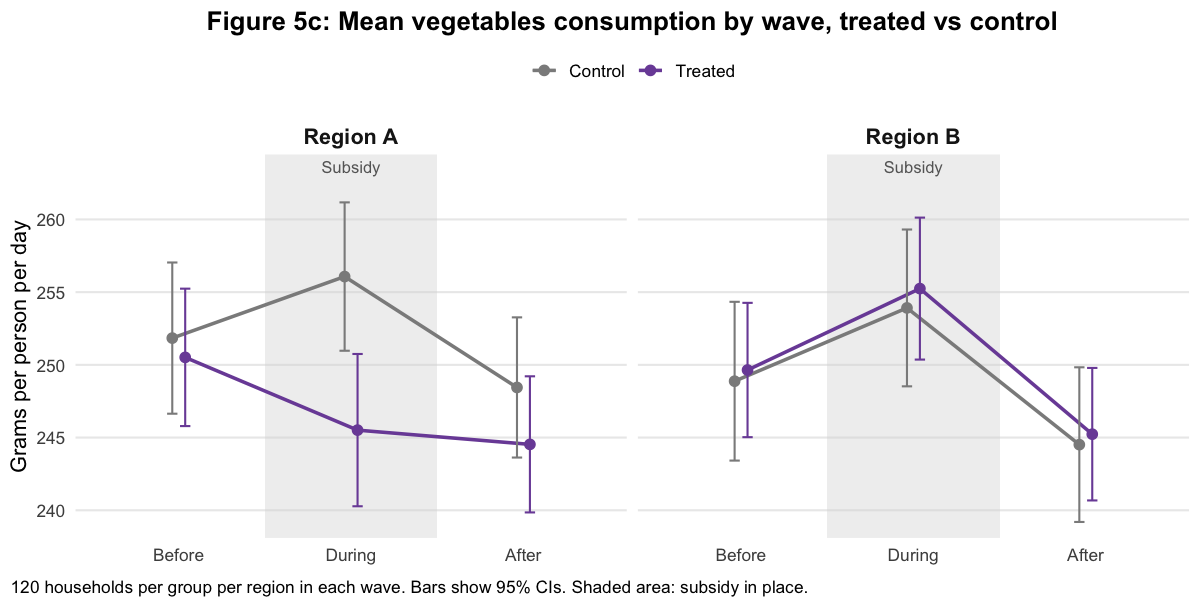

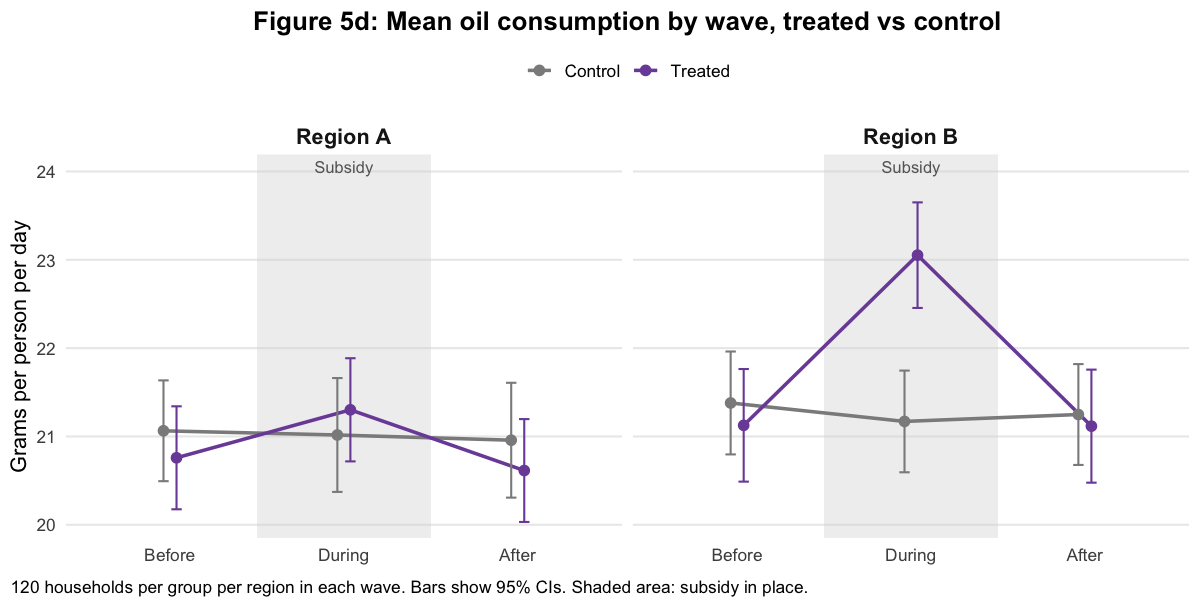

In [22]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# Data: mean and SE of grams consumed by food, region, wave and group
food_means <- raw_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(food, region, wave, group) |>
  summarise(mean = mean(grams_consumed),
            se = sd(grams_consumed) / sqrt(n()),
            .groups = "drop")

foods <- c("rice", "fish", "vegetables", "oil")

# One figure per food
for (f in foods) {
  p <- ggplot(filter(food_means, food == f), aes(wave, mean, colour = group, group = group)) +

    # Shaded area and label for the During wave (subsidy in place)
    annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
             ymax = Inf, fill = "grey85", alpha = 0.4) +
    annotate("text", x = 2, y = Inf, label = "Subsidy",
             vjust = 1.5, colour = "grey40", size = 3.5) +

    # Means with 95% confidence intervals
    geom_line(position = dodge, linewidth = 1) +
    geom_point(position = dodge, size = 2.5) +
    geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                  width = 0.12, position = dodge) +

    # One panel per region
    facet_wrap(~ region) +

    # Scales: discrete x axis, extra space on top for the label, group colours
    scale_x_discrete() +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
    scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

    # Titles and notes
    labs(title = paste0("Figure 5", letters[which(foods == f)], ": Mean ", f, " consumption by wave, treated vs control"),
         x = NULL, y = "Grams per person per day", colour = NULL,
         caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

    # Visual style
    theme_minimal(base_size = 13) +
    theme(legend.position = "top",
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          strip.text = element_text(face = "bold", size = 13),
          plot.title = element_text(face = "bold", hjust = 0.5),
          plot.caption = element_text(hjust = 0, vjust = -1),
          plot.caption.position = "plot")

  print(p)
}


It is important to take into account what Figure 6 shows. The bars for each food add up to the total effect of the subsidy on calorie intake in each region. For region A, we can clearly see that there are two dominating effects: the calories from fish increased, while the calories from rice decreased by much more. This is compatible with what we estimated in Tables 4, 5 and 6, since households replaced rice with fish, which provides fewer calories per gram.

However, for region B the effect on calories from rice is positive but not statistically significant, and the increase is mainly driven by oil (Table 6). This explains why the households in this region experienced an increase in calorie intake. This does not imply that region B is eating healthier, since we do not have information about the evolution in the consumption of micronutrients or proteins. For the same reason, we cannot say that region A is eating worse, as fish may provide more protein than rice.

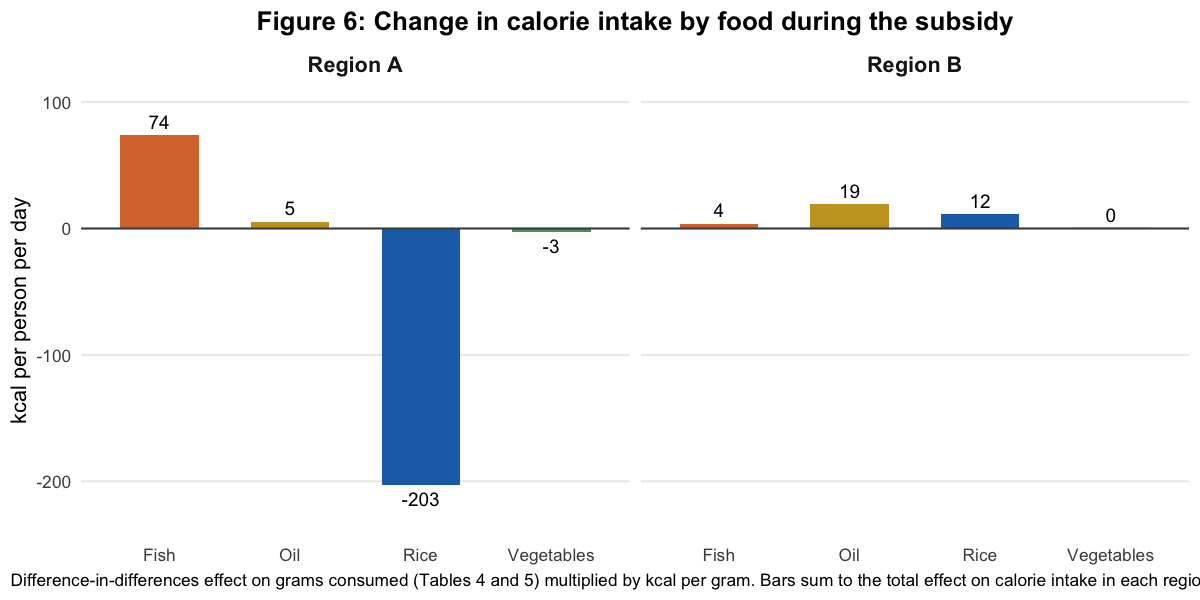

In [23]:
kcal_per_g <- c(rice = 3.6, fish = 1.2, vegetables = 0.3, oil = 9.0)

# Effect of the subsidy on calories from each food, by region
decomp <- expand_grid(food = names(kcal_per_g), region = c("A", "B")) |>
  rowwise() |>
  mutate(grams = coef(regression_per_food(food, region))["treated:wave_during"]) |>
  ungroup() |>
  mutate(kcal   = grams * kcal_per_g[food],
         food   = str_to_title(food),
         region = paste("Region", region))

# Diverging bar chart
options(repr.plot.width = 10, repr.plot.height = 5)

ggplot(decomp, aes(food, kcal, fill = food)) +
  geom_col(width = 0.6) +
  geom_hline(yintercept = 0, colour = "grey30") +
  geom_text(aes(label = round(kcal), vjust = if_else(kcal >= 0, -0.5, 1.5)), size = 4) +
  facet_wrap(~ region) +
  scale_fill_manual(values = c(Rice = "#1f6fb4", Oil = "#c9a227",
                               Fish = "#d9773b", Vegetables = "#5a9e5f"),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = 0.15)) +
  labs(title = "Figure 6: Change in calorie intake by food during the subsidy",
       x = NULL, y = "kcal per person per day",
       caption = "Difference-in-differences effect on grams consumed (Tables 4 and 5) multiplied by kcal per gram. Bars sum to the total effect on calorie intake in each region.") +
  theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

It is also important to consider how the subsidy changes the way households allocate their resources between food and other goods. Table 7 shows that this differs between regions. Since cash resources do not change, any increase in food spending implies an equal decrease in other spending. On the one hand, in region A the subsidy led households to spend more on food than control households, even though rice became cheaper, because they spent much more on fish. They spent on fish all the money saved on rice and also reduced their spending on other goods.

On the other hand, in region B households spent less on food than control households. Most of the money freed by the subsidy went to other goods, and only a small part went to oil and fish.

In [16]:
spend_data <- filter(food_data, food == "rice")

spend_model <- function(v, r) {
  feols(as.formula(paste(v, "~ treated:wave_during + treated:wave_after | household_id + wave")),
        data = filter(spend_data, region == r), cluster = ~household_id)
}

tbl8 <- modelsummary(list("Food spending, A"  = spend_model("food_spending", "A"),
                          "Food spending, B"  = spend_model("food_spending", "B"),
                          "Other spending, A" = spend_model("other_spending", "A"),
                          "Other spending, B" = spend_model("other_spending", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs"),
                     output  = "gt") |>
  tab_header(title = "Table 7: Effect of the rice subsidy on spending, by region") |>
  tab_source_note("Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl8))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


An alternative explanation for region B is that households already cover their food needs, so their demand for food does not respond to the lower price of rice. In that case, they keep buying the same amount of rice and spend the money saved on other goods instead of on more food. The evidence for region B is consistent with this explanation: rice consumption does not change significantly (Tables 5 and 6) and food spending falls (Table 7).

This explanation cannot account for region A, where food spending rises. There, the money freed by the subsidy did not go to other goods but to fish, which is consistent with the proposed Giffen-type mechanism, although it does not establish the separate income and substitution effects. However, the data only describe how households reallocated their spending; they cannot tell us why preferences differ between the two regions.

##### Question 7: Brief the policymaker
*Write a 200–300 word briefing answering the government’s question: should it expand, revise or discontinue the programme? Ground your recommendation in your evidence and explain the main mechanism in plain language.*

*Does your verdict on the policy’s stated objective also determine whether households are better orworse off? Explain. Identify the most useful additional evidence or policy test before a final decision, and be clear about the limits of what this pilot establishes.*

The analysis shows that the subsidy does not have a positive effect for all households in the regions where the pilot operated. In particular, region A experienced a fall in calorie intake per person, as lower demand for rice was accompanied by the purchase of foods with fewer calories per gram, mainly fish. It is worth noting that in this region the subsidy also led to higher spending on food. In this sense, rather than assessing calorie intake alone, it would be worth measuring the impact on micronutrients and protein in this region: the shift toward fish may raise protein intake, although the fall in vegetables may reduce some micronutrients.

In parallel, region B shows an increase in calorie intake, explained mainly by higher consumption of oil and, to a lesser extent, fish, while rice and vegetables remain constant. Households bought the same amount of rice at a lower price, and most of the money saved was spent on goods other than food, so their food spending decreased. This may indicate that calorie needs in this region were already met in the Before wave, although the two regions look very similar at baseline, so the data cannot confirm this. In this sense, it would be worth checking whether the subsidy affects the intake of protein or other micronutrients before deciding in which region the programme should focus.